<h1><bold>Comment Category Prediction Challenge</bold></h1>

<p>This project focuses on building a multi-class classification model to predict how an online platform categorizes user-generated comments. Using a combination of textual data, engagement signals (upvotes/downvotes), emoticon indicators, and topic-related flags, we apply machine learning techniques to accurately determine the final label assigned to each comment.</p>

<h2>Dataset Overview</h2>

<table border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th>Feature Name</th>
    <th>Data Type</th>
    <th>Description</th>
  </tr>
  <tr>
    <td>comment</td>
    <td>Text (String)</td>
    <td>Raw textual content of the user comment</td>
  </tr>
  <tr>
    <td>created_date</td>
    <td>DateTime</td>
    <td>Date and time when the comment was posted</td>
  </tr>
  <tr>
    <td>post_id</td>
    <td>Categorical / String</td>
    <td>Unique identifier linking the comment to a discussion thread</td>
  </tr>
  <tr>
    <td>emoticon_1</td>
    <td>Binary (0/1)</td>
    <td>Indicator for presence of first emoticon group</td>
  </tr>
  <tr>
    <td>emoticon_2</td>
    <td>Binary (0/1)</td>
    <td>Indicator for presence of second emoticon group</td>
  </tr>
  <tr>
    <td>emoticon_3</td>
    <td>Binary (0/1)</td>
    <td>Indicator for presence of third emoticon group</td>
  </tr>
  <tr>
    <td>upvote</td>
    <td>Integer</td>
    <td>Number of positive reactions received</td>
  </tr>
  <tr>
    <td>downvote</td>
    <td>Integer</td>
    <td>Number of negative reactions received</td>
  </tr>
  <tr>
    <td>if_1</td>
    <td>Numeric (Integer/Float)</td>
    <td>Internal platform feature (hidden meaning)</td>
  </tr>
  <tr>
    <td>if_2</td>
    <td>Numeric (Integer/Float)</td>
    <td>Second internal platform feature (hidden meaning)</td>
  </tr>
  <tr>
    <td>race</td>
    <td>Binary (0/1)</td>
    <td>Indicates reference to race-related topic</td>
  </tr>
  <tr>
    <td>religion</td>
    <td>Binary (0/1)</td>
    <td>Indicates reference to religion-related topic</td>
  </tr>
  <tr>
    <td>gender</td>
    <td>Binary (0/1)</td>
    <td>Indicates reference to gender-related topic</td>
  </tr>
  <tr>
    <td>disability</td>
    <td>Binary (0/1)</td>
    <td>Indicates reference to disability-related topic</td>
  </tr>
  <tr>
    <td>label</td>
    <td>Categorical (Target - 4 Classes)</td>
    <td>Final category assigned to the comment (Only in train dataset)</td>
  </tr>
</table>

<h2>Top Performing Models</h2>

<table>
    <tr>
        <th>Model</th>
        <th>F1 Score</th>
    </tr>
    <tr>
        <td>LGBM</td>
        <td>0.81</td>
    </tr>
        <tr>
        <td>LR</td>
        <td>0.76</td>
    </tr>
        <tr>
        <td>SVC</td>
        <td>0.74</td>
    </tr>
    
</table>

In [57]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


<h2>1. Importing Libraries</h2>

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

<h2>2. Loading Datasets</h2>

In [59]:
df1 = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/test.csv')
df2 = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/train.csv')

In [60]:
test_df = df1
train_df = df2
print(f'Loaded Data => Test:{len(test_df)} train:{len(train_df)}')

Loaded Data => Test:102000 train:198000


<h2>3. Preprocessing</h2>

In [61]:
print(f'Train Shape:{train_df.shape}')
print(f'Test Shape:{test_df.shape}')

Train Shape:(198000, 15)
Test Shape:(102000, 14)


In [62]:
print('==Train DF==')
train_df.isna().sum()

==Train DF==


created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64

In [63]:
print('==Test DF==')
test_df.isna().sum()

==Test DF==


created_date        0
post_id             0
emoticon_1          0
emoticon_2          0
emoticon_3          0
upvote              0
downvote            0
if_1                0
if_2                0
race            75269
religion        75269
gender          75269
disability          0
comment             0
dtype: int64

In [64]:
train_df.describe()

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,label
count,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000
mean,68.447429,0.279768,0.048338,0.121071,2.607975,0.666394,1.906152,7.956212,0.793965
std,27.948390,1.023234,0.258477,0.481013,5.054763,2.044335,25.635752,14.839464,0.979808
min,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000
25%,39.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000
50%,72.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,6.000000,0.000000
75%,72.000000,0.000000,0.000000,0.000000,3.000000,1.000000,4.000000,10.000000,2.000000
max,129.000000,47.000000,11.000000,17.000000,201.000000,107.000000,1860.000000,1833.000000,3.000000


In [65]:
test_df.describe()

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2
count,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000
mean,68.359422,0.280078,0.048353,0.118902,2.609402,0.661667,1.903078,7.956206
std,27.923491,1.043353,0.257278,0.480484,4.966033,1.965536,26.273483,15.186746
min,24.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
25%,39.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
50%,72.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,6.000000
75%,72.000000,0.000000,0.000000,0.000000,3.000000,1.000000,4.000000,10.000000
max,129.000000,95.000000,8.000000,19.000000,189.000000,95.000000,1866.000000,1798.000000


In [66]:
train_df['comment'][4]

'Today, the confederate flag...tomorrow, the nazi flag...school children don\'t have the same free speech rights in, on or near public school property as adults in public... maybe you don\'t remember "Bong hits for Jesus"...perhaps ya outta get out more. ep'

In [67]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)  
    text = re.sub(r"[^a-z\s]", " ", text) 
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [68]:
train_df["comment"] = train_df["comment"].apply(clean_text)
test_df["comment"] = test_df["comment"].apply(clean_text)

In [69]:
train_df['comment'][4]

'today the confederate flag tomorrow the nazi flag school children don t have the same free speech rights in on or near public school property as adults in public maybe you don t remember bong hits for jesus perhaps ya outta get out more ep'

In [70]:
# downvote if_1 if_2
print(train_df['if_1'].unique())

[   0    6    4    5   10    7    9 1800 1569 1538   12   11 1814  249
  250 1815 1560 1263 1545 1267 1258 1543 1277 1830 1585    8 1257 1807
 1810 1783 1777 1848 1548 1232 1572 1583 1576 1256 1566 1547 1551 1825
 1271 1838 1553 1846 1558 1557 1767 1819 1581 1254 1811 1860 1778 1827
 1584]


In [71]:
train_df['race'].unique()
# print(len(train_df['race'].unique()))

array([nan, 'none', 'white', 'other', 'asian', 'black', 'latino'],
      dtype=object)

In [72]:
test_df['race'].unique()
# print(len(test_df['race'].unique()))

array([nan, 'black', 'other', 'none', 'asian', 'white', 'latino'],
      dtype=object)

In [73]:
train_df['gender'].unique()

array([nan, 'none', 'male', 'female', 'transgender', 'other'],
      dtype=object)

In [74]:
test_df['gender'].unique()

array([nan, 'male', 'none', 'female', 'transgender', 'other'],
      dtype=object)

In [75]:
train_df['religion'].unique()

array([nan, 'christian', 'muslim', 'none', 'jewish', 'atheist', 'other',
       'hindu', 'buddhist'], dtype=object)

In [76]:
test_df['religion'].unique()

array([nan, 'none', 'buddhist', 'atheist', 'muslim', 'christian', 'other',
       'jewish', 'hindu'], dtype=object)

In [77]:
train_df['disability'].unique()

array([False,  True])

In [78]:
test_df['disability'].unique()

array([False,  True])

In [79]:
import numpy as np

train_df = train_df.replace("none", np.nan)
test_df = test_df.replace("none", np.nan)

<h2>4. Exploratory Data Analysis</h2>

In [80]:
train_df.columns

Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment', 'label'],
      dtype='object')

In [81]:
train_df['label'].value_counts(normalize=True)*100

label
0    57.663131
2    31.535354
1     8.039394
3     2.762121
Name: proportion, dtype: float64

<Axes: title={'center': 'Label Frequency Count'}, xlabel='label'>

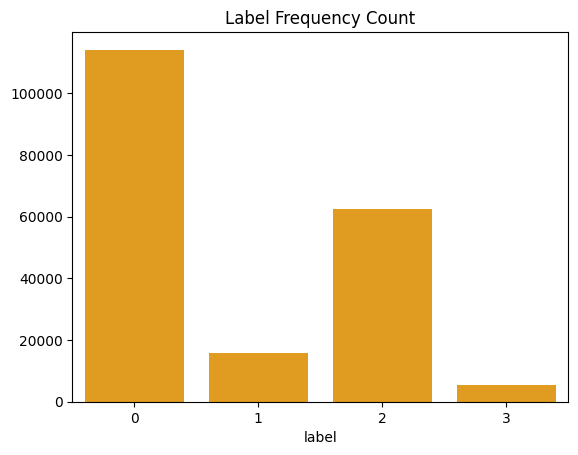

In [82]:
import seaborn as sns
plt.title('Label Frequency Count')
sns.barplot(x=train_df['label'].value_counts().index,y=train_df['label'].value_counts().values,color='orange')

In [83]:
train_df['disability'].value_counts(normalize=True)*100

disability
False    98.614646
True      1.385354
Name: proportion, dtype: float64

In [84]:
train_df.groupby('gender')['label'].count()

gender
female         8037
male           7549
other           208
transgender     622
Name: label, dtype: int64

<Axes: title={'center': 'Gender wise label count'}, xlabel='label', ylabel='count'>

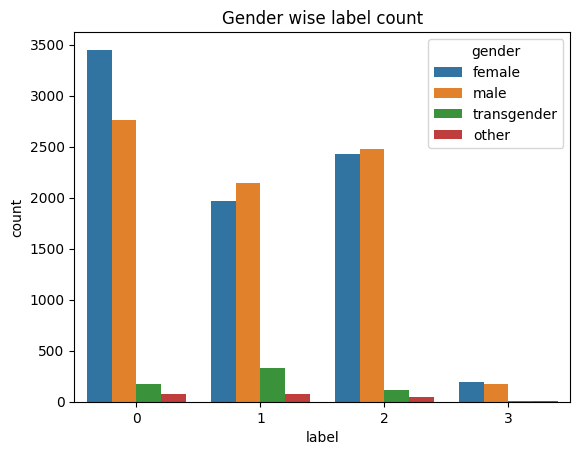

In [85]:
import seaborn as sns
plt.title('Gender wise label count')
sns.countplot(x=train_df['label'],hue=train_df['gender'])

<Axes: title={'center': 'disability wise label count'}, xlabel='label', ylabel='count'>

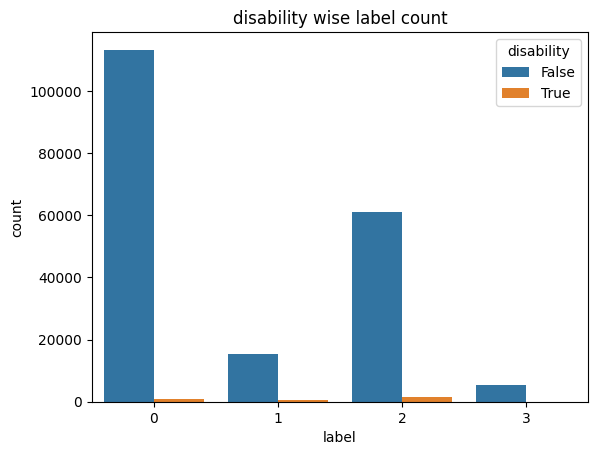

In [86]:
import seaborn as sns
plt.title('disability wise label count')
sns.countplot(x=train_df['label'],hue=train_df['disability'])

<Axes: >

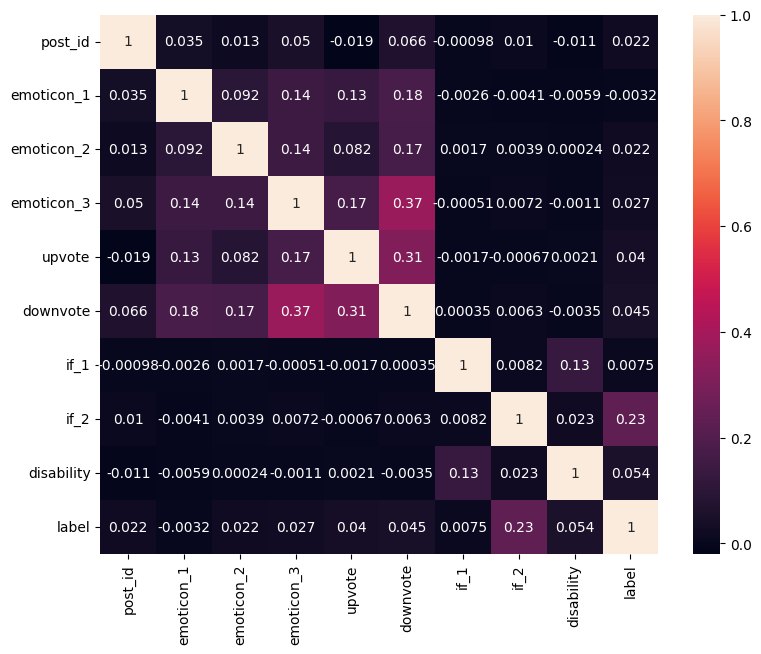

In [87]:
import seaborn as sns
plt.figure(figsize=(9,7))
corr_mat = train_df.corr(numeric_only=True)
sns.heatmap(corr_mat,annot=True)

In [88]:
# -1 +1
# [1,2,3]
# [0.6,3,0.9]
# correlation

## 5. Feature Engnieering

In [89]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer

In [90]:
text_cols = ["comment"]
numeric_cols = ["emoticon_1", "emoticon_2", "emoticon_3",
    "upvote", "downvote",
    "if_1", "if_2","text_len","word_count"
]
categorical_cols = ["race","religion","gender"]

binary_cols =["disability"]

In [91]:
# Train
train_df["text_len"] = train_df["comment"].fillna("").apply(len)
train_df["word_count"] = train_df["comment"].fillna("").apply(lambda x: len(x.split()))

# Test
test_df["text_len"] = test_df["comment"].fillna("").apply(len)
test_df["word_count"] = test_df["comment"].fillna("").apply(lambda x: len(x.split()))

In [92]:
# -visulation
# -feature imp(reason)
# -english commu
# -others
# -practice data
# -

In [93]:
text_transformer = Pipeline([
    ('tfidf',TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),   
    min_df=3,
    max_df=0.85,
    sublinear_tf=True,
    stop_words="english"
))
])

In [94]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

In [95]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [96]:
preprocessor = ColumnTransformer([
    ("text", text_transformer, "comment"),
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols),
    ("bin", "passthrough", binary_cols)
])

In [97]:
train_df["comment"] = train_df["comment"].fillna("")
test_df["comment"] = test_df["comment"].fillna("")

In [98]:
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=["label", "post_id", "created_date"])
y = train_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y 
)

## 6. Model Training

In [99]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
    max_iter=3000,            
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
))
])

In [100]:
# log_model.fit(X_train, y_train)

In [101]:
from sklearn.svm import LinearSVC

model_svc = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LinearSVC(
        class_weight="balanced",
        max_iter=5000
    ))
])

In [102]:
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# model = Pipeline([
#     ("preprocessor", preprocessor),
#      ("clf", lgb.LGBMClassifier(
#     n_estimators=900,
#     learning_rate=0.035,
#     num_leaves=50,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     min_child_samples=40,
#     reg_alpha=0.8,
#     reg_lambda=2.0,
#     class_weight={0:1, 1:1.2, 2:1, 3:1.8},
#     force_col_wise=True,
#     n_jobs=-1,
#     verbose=-1
# ))
# ])

In [103]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from sklearn.pipeline import Pipeline

log_clf = LogisticRegression(
    max_iter=5000,
    C=10,
    class_weight="balanced",
    n_jobs=-1
)

lgb_clf = lgb.LGBMClassifier(
    n_estimators=900,
    learning_rate=0.035,
    num_leaves=50,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=40,
    reg_alpha=0.8,
    reg_lambda=2.0,
    class_weight={0:1, 1:1.3, 2:1, 3:2.5},
    force_col_wise=True,
    n_jobs=-1,
    verbose=-1
)

# Voting model
voting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", VotingClassifier(
        estimators=[
            ("lr", log_clf),
            ("lgb", lgb_clf)
        ],
        voting="soft",
        weights=[1, 3]  
    ))
])

In [104]:
voting_model.fit(X_train, y_train)

KeyboardInterrupt: 

## 7. Hyper Parameter Tuning

In [ ]:
param_grid = {
    "clf__n_estimators": [700, 800],             
    "clf__learning_rate": [0.035, 0.04],         
    "clf__num_leaves": [63, 80],                  
    "clf__min_child_samples": [20, 30],           
    "clf__subsample": [0.8],
    "clf__colsample_bytree": [0.7, 0.8],
    "clf__reg_alpha": [0.3, 0.5],
    "clf__reg_lambda": [1.5, 2.0]
}

In [ ]:
# from sklearn.model_selection import GridSearchCV
# grid = GridSearchCV(
#     model,
#     param_grid,
#     cv=3,
#     scoring="f1_macro",
#     n_jobs=-1,
#     verbose=1
# )
# # grid.fit(X_train, y_train)

In [ ]:
# best_model = grid.best_estimator_

In [ ]:
# best_model.fit(X_train, y_train)

## 8. Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score
y_pred = voting_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

## 9. Submission File Creation

In [ ]:
X_test_final = test_df.drop(columns=["post_id", "created_date"])

In [ ]:
test_predictions = voting_model.predict(X_test_final)

In [ ]:
sample_sub = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/Sample.csv')

sample_sub["label"] = test_predictions

sample_sub.to_csv("/kaggle/working/submission.csv", index=False)
print("Submission file created successfully!")

In [ ]:
# sample_sub = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/Sample.csv')
# print(sample_sub.columns)

In [ ]:
# Dummy Submission
# import pandas as pd
# train_df = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/train.csv')

# mean_label = train_df['label'].mean()
# print("Calculated Mean Label:", mean_label)

# submission_df = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/Sample.csv')

# submission_df['label'] = int(round(mean_label, 0))

# submission_path = '/kaggle/working/submission.csv'
# submission_df.to_csv(submission_path, index=False)

# print("File saved at:", submission_path)

In [ ]:
# # ===Milestone 1===
# print('shape')
# print(train_df.shape)

# print('length of test df')
# print(len(test_df))

# print('data types')
# print(train_df.dtypes)

# print('Na values')
# print(train_df.isna().sum())

# print('different labels')
# print(train_df['label'].unique())

# print('labels percentage')
# print(train_df['label'].value_counts(normalize=True) * 100)

# print('median upvote')
# print(train_df['upvote'].median())

# print('max among all')
# print(train_df['if_2'].max(),
# train_df['upvote'].max(),
# train_df['downvote'].max(),
# train_df['if_1'].max())

# print('min if2')
# train_df['if_2'].min()

In [ ]:
# df = train_df


In [ ]:
# df['comment'].str.strip().eq('').sum()

In [ ]:
# M2
# # 1
# df['created_date'] = pd.to_datetime(df['created_date'])
# df['created_date'].dt.month_name().str.lower().value_counts().idxmax()

In [ ]:
# # 2
# df["total_emoticons"] = df["emoticon_1"] + df["emoticon_2"] + df["emoticon_3"]
# df["total_emoticons"].max()

In [ ]:
# # 3
# df["comment"] = df["comment"].fillna("")
# median_len = df[df["label"] == 3]["comment"].str.len().median()
# median_len

In [ ]:
# # 4
# min_up = df["upvote"].min()
# max_up = df["upvote"].max()
# scaled_value = (10 - min_up) / (max_up - min_up)
# scaled_value

In [ ]:
# # 5
# avg_words = (
#     df[df["label"] == 1]["comment"]
#     .fillna("")
#     .apply(lambda x: len(x.split()))
#     .mean()
# )
# round(avg_words, 2)

In [ ]:
# # 6
# df["comment"].str.contains("trump", case=False, na=False).sum()

In [ ]:
# # 7
# import string
# stop_words = ['a','an','the','and','or','but','if','because','as','of','at','by','for','with','about','to','from','up','on','in','out','over','under','is','are','was','were','be','been','being','have','has','had','do','does','did','it','its','they','them','their','she','her','he','him','his','this','that','which','who','whom','i','me','my','we','our','you','your']
# text = df.loc[0,"comment"]
# text = text.translate(str.maketrans('', '', string.punctuation))
# words = text.lower().split()
# filtered_words = [w for w in words if w not in stop_words]

# len(filtered_words)

In [ ]:
# # 8
# tokens = set()
# for comment in df["comment"].fillna("").str.lower():
#     tokens.update(comment.split())
# len(tokens)

In [ ]:
# # 9
# from sklearn.feature_extraction.text import TfidfVectorizer
# vectorizer = TfidfVectorizer(
#     stop_words="english",
#     min_df=5,
#     ngram_range=(1,2)
# )
# X = vectorizer.fit_transform(df["comment"].fillna(""))

# len(vectorizer.get_feature_names_out())

In [ ]:
# M3
# # 1
# from sklearn.model_selection import train_test_split
# X = df.drop(columns=["label"])
# y = df["label"]

# X_train, X_val, y_train, y_val = train_test_split(
#     X, y,
#     test_size=0.2,
#     random_state=42
# )
# a = X_train.shape[0]
# c = X_val.shape[0]

# print( a + c)

In [ ]:
# # 2
# X_train["created_date"] = pd.to_datetime(X_train["created_date"])
# X_train["month"] = X_train["created_date"].dt.month_name()
# X_train["month"].value_counts().idxmax()

In [ ]:
# df.columns

In [ ]:
# # 3
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import OneHotEncoder
# import pandas as pd

# # categorical columns to process
# cat_cols = ["religion", "gender", "race"]

# # Step 1: impute missing values
# imputer = SimpleImputer(strategy="constant", fill_value="none")

# X_train[cat_cols] = imputer.fit_transform(X_train[cat_cols])
# X_val[cat_cols] = imputer.transform(X_val[cat_cols])

# # Step 2: OneHotEncode
# ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# train_encoded = ohe.fit_transform(X_train[cat_cols])
# val_encoded = ohe.transform(X_val[cat_cols])

# # convert to dataframe
# train_encoded_df = pd.DataFrame(
#     train_encoded,
#     columns=ohe.get_feature_names_out(cat_cols),
#     index=X_train.index
# )

# val_encoded_df = pd.DataFrame(
#     val_encoded,
#     columns=ohe.get_feature_names_out(cat_cols),
#     index=X_val.index
# )

# # drop original categorical columns
# X_train = X_train.drop(columns=cat_cols)
# X_val = X_val.drop(columns=cat_cols)

# # concat encoded columns
# X_train = pd.concat([X_train, train_encoded_df], axis=1)
# X_val = pd.concat([X_val, val_encoded_df], axis=1)

# print(X_train.shape)

In [ ]:
# # 4
# from sklearn.feature_extraction.text import CountVectorizer

# cv = CountVectorizer()

# X_train_counts = cv.fit_transform(X_train["comment"].fillna(""))
# X_val_counts = cv.transform(X_val["comment"].fillna(""))

# X_train_counts[1].sum()

In [ ]:
# # 5
# X_train["disability"] = X_train["disability"].astype(int)
# X_val["disability"] = X_val["disability"].astype(int)

# total_disability = X_train["disability"].sum() + X_val["disability"].sum()

# print(total_disability)


In [ ]:
# # 6
# from sklearn.preprocessing import StandardScaler

# X_train_num = X_train.drop(columns=["created_date"], errors="ignore")
# X_val_num = X_val.drop(columns=["created_date"], errors="ignore")

# num_cols = X_train_num.select_dtypes(include=["int64","float64"]).columns

# scaler = StandardScaler()

# scaler.fit(X_train_num[num_cols])

# print(len(num_cols))

In [ ]:
# # 7
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.metrics import f1_score
# from sklearn.naive_bayes import MultinomialNB
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import OneHotEncoder

# X = df.drop(columns=["label"])
# y = df["label"]

# X_train, X_val, y_train, y_val = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# X_train["created_date"] = pd.to_datetime(X_train["created_date"])
# X_val["created_date"] = pd.to_datetime(X_val["created_date"])

# for d in [X_train, X_val]:
#     d["day"] = d["created_date"].dt.day
#     d["month"] = d["created_date"].dt.month
#     d["year"] = d["created_date"].dt.year
#     d.drop(columns=["created_date"], inplace=True)

# text_col = "comment"

# cat_cols = ["religion","gender","race"]

# preprocessor = ColumnTransformer([
#     ("text", TfidfVectorizer(stop_words="english"), text_col),
#     ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
# ], remainder="passthrough")

# model = Pipeline([
#     ("prep", preprocessor),
#     ("nb", MultinomialNB())
# ])

# model.fit(X_train, y_train)

# train_pred = model.predict(X_train)

# f1_score(y_train, train_pred, average="macro")

In [ ]:
# # 8
# val_pred = model.predict(X_val)
# f1_score(y_val, val_pred, average="macro")

In [ ]:
# for d in [X_train, X_val]:
#     if 'created_date' in d.columns:
#         d['created_date'] = pd.to_datetime(d['created_date'])
#         d['day'] = d['created_date'].dt.day
#         d['month'] = d['created_date'].dt.month
#         d['year'] = d['created_date'].dt.year
#         d['is_weekend'] = d['created_date'].dt.dayofweek.isin([5,6]).astype(int)
#         d.drop(columns=['created_date'], inplace=True)

In [ ]:
# # 10
# train_pred = model.predict(X_train)
# f1_score(y_train, train_pred, average="macro")

In [ ]:
# # 11
# val_pred = model.predict(X_val)
# f1_score(y_val, val_pred, average="macro")

In [ ]:
# M5
# import pandas as pd
# import numpy as np
# import scipy.sparse as sp
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.preprocessing import OneHotEncoder
# from sklearn.compose import ColumnTransformer
# from sklearn.model_selection import train_test_split, GridSearchCV
# from sklearn.naive_bayes import MultinomialNB
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, classification_report

In [ ]:
# df = train_df.copy()
# y  = df['label']
# df = df.drop(columns=['label'])
# test = test_df.copy()

In [ ]:
# #1
# for d in [df, test]:
#     d['created_date'] = pd.to_datetime(d['created_date'])
#     d['year'] = d['created_date'].dt.year
#     d['month'] = d['created_date'].dt.month
#     d['hour'] = d['created_date'].dt.hour
#     d.drop(columns=['created_date'], inplace=True)

# #2:
# cat_cols = ['race', 'religion', 'gender']
# for d in [df, test]:
#     d[cat_cols] = d[cat_cols].fillna("Unknown")
#     d['comment'] = d['comment'].fillna("")
#     d['disability'] = d['disability'].astype(int)

# #3
# text_col = 'comment'

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('tfidf', TfidfVectorizer(stop_words="english", max_features=5000), text_col),
#         ('cat', OneHotEncoder(drop="first", handle_unknown='ignore'), cat_cols)
#     ],
#     remainder='passthrough'
# )
# X = preprocessor.fit_transform(df)
# X_test = preprocessor.transform(test)
# X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
# max_tfidf_features = 5000


# print("Q1:", max_tfidf_features)
# print("Q2:", X_train.shape[1])
# print("Q3:", X_val.shape[1])


In [ ]:
# # Q4 & Q5: Multinomial Naive Bayes
# nb_model = MultinomialNB()
# nb_model.fit(X_train, y_train)
# y_val_pred_nb = nb_model.predict(X_val)

# acc_nb = accuracy_score(y_val, y_val_pred_nb)
# print("Q4 (Validation Accuracy NB):", round(acc_nb,3))

In [ ]:
# report_nb = classification_report(y_val, y_val_pred_nb, output_dict=True)
# precision_label3_nb = report_nb['3']['precision']
# print("Q5 (Precision for label 3 NB):", round(precision_label3_nb,2))

In [ ]:
# # Q6 Q7 Q8: Logistic R
# lr_model = LogisticRegression(max_iter=500, random_state=42)
# lr_model.fit(X_train, y_train)

# y_val_pred_lr = lr_model.predict(X_val)
# y_train_pred_lr = lr_model.predict(X_train)

# acc_val_lr = accuracy_score(y_val, y_val_pred_lr)
# acc_train_lr = accuracy_score(y_train, y_train_pred_lr)
# print("Q6 (Validation Accuracy LR):", round(acc_val_lr,3))
# print("Q7 (Training Accuracy LR):", round(acc_train_lr,3))

In [ ]:
# report_lr = classification_report(y_val, y_val_pred_lr, output_dict=True)
# precision_label1_lr = report_lr['1']['precision']
# print("Q8 (Precision for label 1", round(precision_label1_lr,3))

In [ ]:
# # Q9 & Q10: GridSearchCV Logistic R
# param_grid = {'C':[0.1, 1, 10]}
# grid = GridSearchCV(LogisticRegression(max_iter=500, random_state=42, solver='liblinear'),
#                     param_grid, cv=3, scoring='accuracy', n_jobs=-1)
# grid.fit(X_train, y_train)
# best_C = grid.best_params_['C']
# y_val_pred_grid = grid.predict(X_val)
# acc_val_grid = accuracy_score(y_val, y_val_pred_grid)

# print("Q9 (Best C):", best_C)
# print("Q10 (Validation Accuracy after tuning):", round(acc_val_grid,2))